In [1]:
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
plt.rcParams['font.size'] = 12

In [76]:
y_count_arr = np.array([1.0000000e+00, 2.0000000e+00, 1.3000000e+01, 3.5000000e+01,
       1.0500000e+02, 3.8300000e+02, 1.3020000e+03, 4.4940000e+03,
       1.3878000e+04, 4.1697000e+04, 1.1783300e+05, 3.1515800e+05,
       7.9120900e+05, 1.8589540e+06, 4.0562000e+06, 8.1980250e+06,
       1.5240063e+07, 2.5990047e+07, 4.0509162e+07, 5.7540244e+07,
       7.4484261e+07, 8.7974615e+07, 9.5233170e+07, 9.4754468e+07,
       8.6784570e+07, 7.3222674e+07, 5.7391974e+07, 4.2659161e+07,
       3.0726288e+07, 2.1688666e+07, 1.5040715e+07, 1.0281305e+07,
       6.9194860e+06, 4.5976920e+06, 3.0118150e+06, 1.9488540e+06,
       1.2500480e+06, 7.9027900e+05, 4.9651100e+05, 3.0849100e+05,
       1.9017800e+05, 1.1688500e+05, 7.1156000e+04, 4.3329000e+04,
       2.6481000e+04, 1.6151000e+04, 9.8400000e+03, 5.9710000e+03,
       3.6970000e+03, 2.3930000e+03, 1.4840000e+03, 9.3700000e+02,
       6.0300000e+02, 4.1300000e+02, 2.6000000e+02, 1.5900000e+02,
       1.4800000e+02, 8.6000000e+01, 7.9000000e+01, 5.2000000e+01])
x_arr = np.arange(-19.5, 40.5)

In [3]:
(y_count_arr/sum(y_count_arr))[40]

0.00021992655199288706

Text(-10, 1, 'Ru+Ru, Zr+Zr $\\sqrt{s_{\\mathrm{NN}}}=200$ GeV, 0-20%\nrun days 112-118\nanti-$k_{\\mathrm{T}}$, $R=0.4$, $p_{\\mathrm{T}}>15$ GeV$/c$')

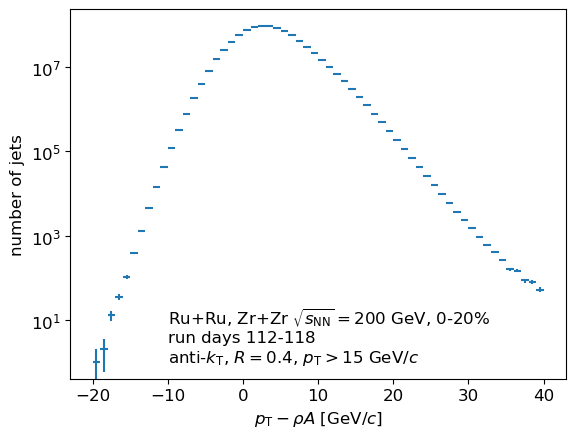

In [5]:
plt.errorbar(x_arr, y_count_arr, xerr=0.5, yerr=np.sqrt(y_count_arr), ls='none')
plt.ylabel('number of jets')
plt.xlabel(r'$p_{\mathrm{T}}-\rho A$ [GeV$/c$]')
plt.yscale('log')
plt.text(-10, 1, r'Ru+Ru, Zr+Zr $\sqrt{s_{\mathrm{NN}}}=200$ GeV, 0-20%'+'\nrun days 112-118\nanti-$k_{\mathrm{T}}$, $R=0.4$, $p_{\mathrm{T}}>15$ GeV$/c$')

In [77]:
y_arr = y_count_arr/sum(y_count_arr)
yerr_arr = np.sqrt(y_count_arr)/sum(y_count_arr)

In [69]:
def gauss(x, A, x0, sigma): 
    return A * np.exp(-(x - x0) ** 2 / (2 * sigma ** 2))

In [100]:
print(x_arr[10:20])

[-9.5 -8.5 -7.5 -6.5 -5.5 -4.5 -3.5 -2.5 -1.5 -0.5]


In [101]:
from scipy.optimize import curve_fit
popt, pcov = curve_fit(gauss, x_arr[10:20], y_arr[10:20], sigma=yerr_arr[10:20])

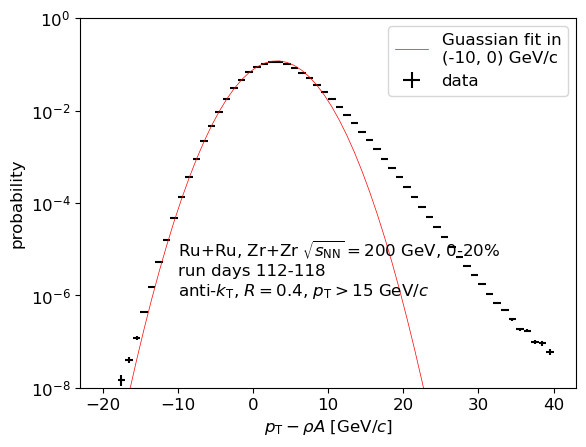

In [102]:
plt.errorbar(x_arr, y_arr, xerr=0.5, yerr=yerr_arr, color='k', ls='none', label='data')
plt.ylabel('probability')
plt.xlabel(r'$p_{\mathrm{T}}-\rho A$ [GeV$/c$]')
plt.yscale('log')
plt.ylim(1e-8, 1)
plt.text(-10, 0.000001, r'Ru+Ru, Zr+Zr $\sqrt{s_{\mathrm{NN}}}=200$ GeV, 0-20%'+'\nrun days 112-118\nanti-$k_{\mathrm{T}}$, $R=0.4$, $p_{\mathrm{T}}>15$ GeV$/c$')
plt.plot(x_arr, gauss(x_arr, *popt), 'r-', label='Guassian fit in\n(-10, 0) GeV/c', linewidth=0.5)#':\na=%5.1f, b=%5.1f, c=%5.1f' % tuple(popt))
plt.legend()

<ErrorbarContainer object of 3 artists>

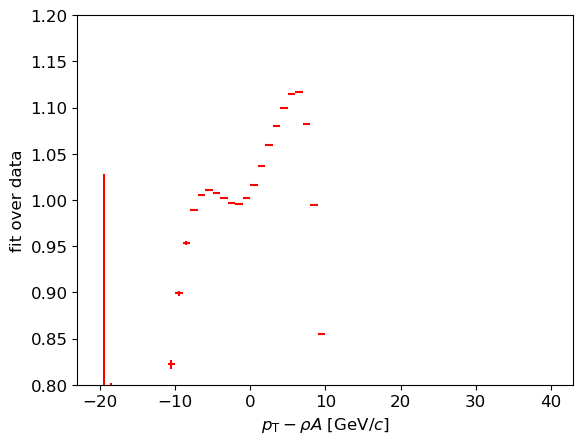

In [103]:
plt.ylabel('fit over data')
plt.xlabel(r'$p_{\mathrm{T}}-\rho A$ [GeV$/c$]')
plt.ylim(0.8,1.2)
#plt.text(-10, 0.000001, r'Ru+Ru, Zr+Zr $\sqrt{s_{\mathrm{NN}}}=200$ GeV, 0-20%'+'\nrun days 115-118\nanti-$k_{\mathrm{T}}$, $R=0.4$, $p_{\mathrm{T}}>15$ GeV$/c$')
plt.errorbar(x_arr, gauss(x_arr, *popt)/y_arr, xerr=0.5, yerr=yerr_arr/y_arr, color='r', ls='none')

In [116]:
print(x_arr[10:23])

[-9.5 -8.5 -7.5 -6.5 -5.5 -4.5 -3.5 -2.5 -1.5 -0.5  0.5  1.5  2.5]


In [117]:
from scipy.optimize import curve_fit
popt, pcov = curve_fit(gauss, x_arr[10:23], y_arr[10:23], sigma=np.sqrt(y_arr)[10:23])

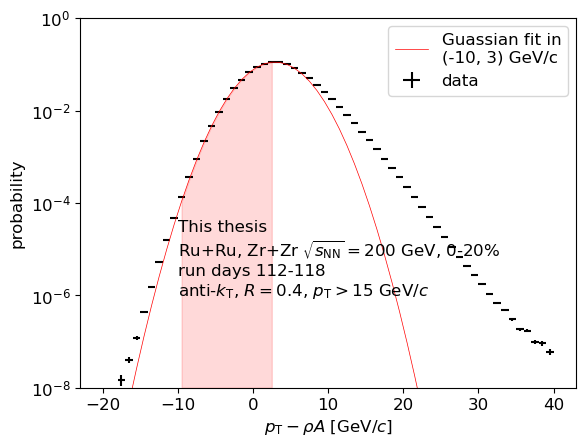

In [129]:
plt.errorbar(x_arr, y_arr, xerr=0.5, yerr=yerr_arr, color='k', ls='none', label='data')
plt.ylabel('probability')
plt.xlabel(r'$p_{\mathrm{T}}-\rho A$ [GeV$/c$]')
plt.yscale('log')
plt.ylim(1e-8, 1)
plt.text(-10, 0.000001, 'This thesis\n'+r'Ru+Ru, Zr+Zr $\sqrt{s_{\mathrm{NN}}}=200$ GeV, 0-20%'+'\nrun days 112-118\nanti-$k_{\mathrm{T}}$, $R=0.4$, $p_{\mathrm{T}}>15$ GeV$/c$')
plt.plot(x_arr, gauss(x_arr, *popt), 'r-', label='Guassian fit in\n(-10, 3) GeV/c', linewidth=0.5)#':\na=%5.1f, b=%5.1f, c=%5.1f' % tuple(popt))
plt.fill_between(x_arr[10:23], np.ones(13)*1e-8, gauss(x_arr, *popt)[10:23], color='r', alpha=0.15)
plt.legend()

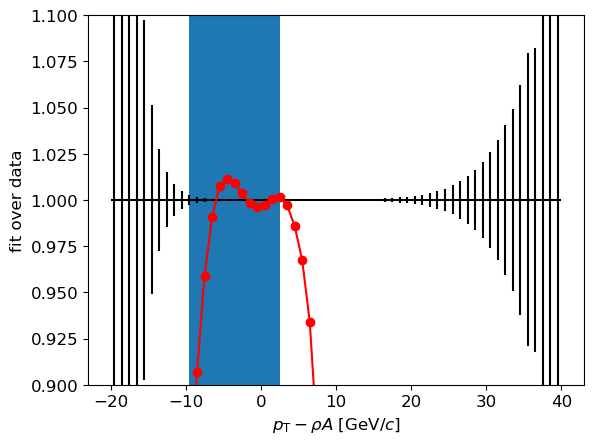

In [120]:
plt.ylabel('fit over data')
plt.xlabel(r'$p_{\mathrm{T}}-\rho A$ [GeV$/c$]')
plt.ylim(0.9,1.1)
#plt.text(-10, 0.000001, r'Ru+Ru, Zr+Zr $\sqrt{s_{\mathrm{NN}}}=200$ GeV, 0-20%'+'\nrun days 115-118\nanti-$k_{\mathrm{T}}$, $R=0.4$, $p_{\mathrm{T}}>15$ GeV$/c$')
plt.errorbar(x_arr, np.ones(len(x_arr)), xerr=0.5, yerr=yerr_arr/y_arr, color='k', ls='none')
plt.fill_between(x_arr[10:23], 0.9, 1.1)
plt.plot(x_arr, gauss(x_arr, *popt)/y_arr, marker='o', color='r')

In [121]:
print(x_arr[15:20])

[-4.5 -3.5 -2.5 -1.5 -0.5]


In [122]:
from scipy.optimize import curve_fit
popt, pcov = curve_fit(gauss, x_arr[15:20], y_arr[15:20], sigma=np.sqrt(y_arr)[15:20])

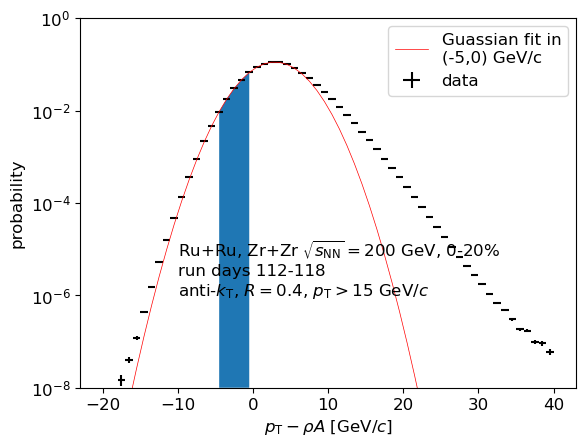

In [123]:
plt.errorbar(x_arr, y_arr, xerr=0.5, yerr=yerr_arr, color='k', ls='none', label='data')
plt.ylabel('probability')
plt.xlabel(r'$p_{\mathrm{T}}-\rho A$ [GeV$/c$]')
plt.yscale('log')
plt.ylim(1e-8, 1)
plt.text(-10, 0.000001, r'Ru+Ru, Zr+Zr $\sqrt{s_{\mathrm{NN}}}=200$ GeV, 0-20%'+'\nrun days 112-118\nanti-$k_{\mathrm{T}}$, $R=0.4$, $p_{\mathrm{T}}>15$ GeV$/c$')
plt.plot(x_arr, gauss(x_arr, *popt), 'r-', label='Guassian fit in\n(-5,0) GeV/c', linewidth=0.5)#':\na=%5.1f, b=%5.1f, c=%5.1f' % tuple(popt))
plt.fill_between(x_arr[15:20], np.ones(5)*1e-8, gauss(x_arr, *popt)[15:20])
plt.legend()

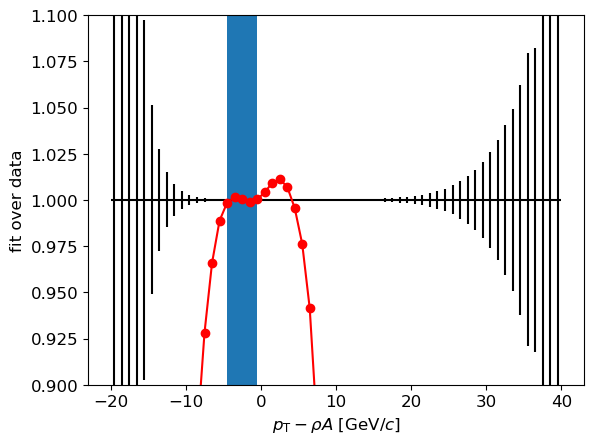

In [124]:
plt.ylabel('fit over data')
plt.xlabel(r'$p_{\mathrm{T}}-\rho A$ [GeV$/c$]')
plt.ylim(0.9,1.1)
#plt.text(-10, 0.000001, r'Ru+Ru, Zr+Zr $\sqrt{s_{\mathrm{NN}}}=200$ GeV, 0-20%'+'\nrun days 115-118\nanti-$k_{\mathrm{T}}$, $R=0.4$, $p_{\mathrm{T}}>15$ GeV$/c$')
plt.errorbar(x_arr, np.ones(len(x_arr)), xerr=0.5, yerr=yerr_arr/y_arr, color='k', ls='none')
plt.plot(x_arr, gauss(x_arr, *popt)/y_arr, marker='o', color='r')
plt.fill_between(x_arr[15:20], 0.9, 1.1)